   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 3.4 MB/s eta 0:00:00
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package fluid-soundfont-gm.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../fluid-soundfont-gm_3.1-5.3_all.deb ...
Unpacking fluid-soundfont-gm (3.1-5.3) ...
Selecting previously unselected package libao-common.
Preparing to unpack .../libao-common_1.2.2+20180113-1.1ubuntu4_all.deb ...
Unpacking libao-common (1.2.2+20180113-1.1ubuntu4) ...
Selecting previously unselected package libao4:amd64.
Preparing to unpack .../libao4_1.2.2+20180113-1.1ubuntu4_amd64.deb ...
Unpacking libao4:amd64 (1.2.2+20180113-1.1ubuntu4) ...
Selecting previously unselected package timidity.
Pre

Processing MIDI files:   0%|          | 0/50 [00:00<?, ?it/s]

Total musical events extracted: 150,003
First 30 events:
['B4', 'G3', 'B4', 'B3', 'D4', 'C5', 'G4', 'A3', '0.2', 'C5', 'G4', 'F#4', '11.0', '0.4', '11.2', 'D4', 'F#4', 'G4', 'B4', 'D5', '6.11', 'G5', 'G4', '0.4', 'G5', '11.2', 'G5', 'C5', 'A3', 'B4']
Total events: 150003
Unique events: 1650
Vocabulary coverage ratio: 0.011


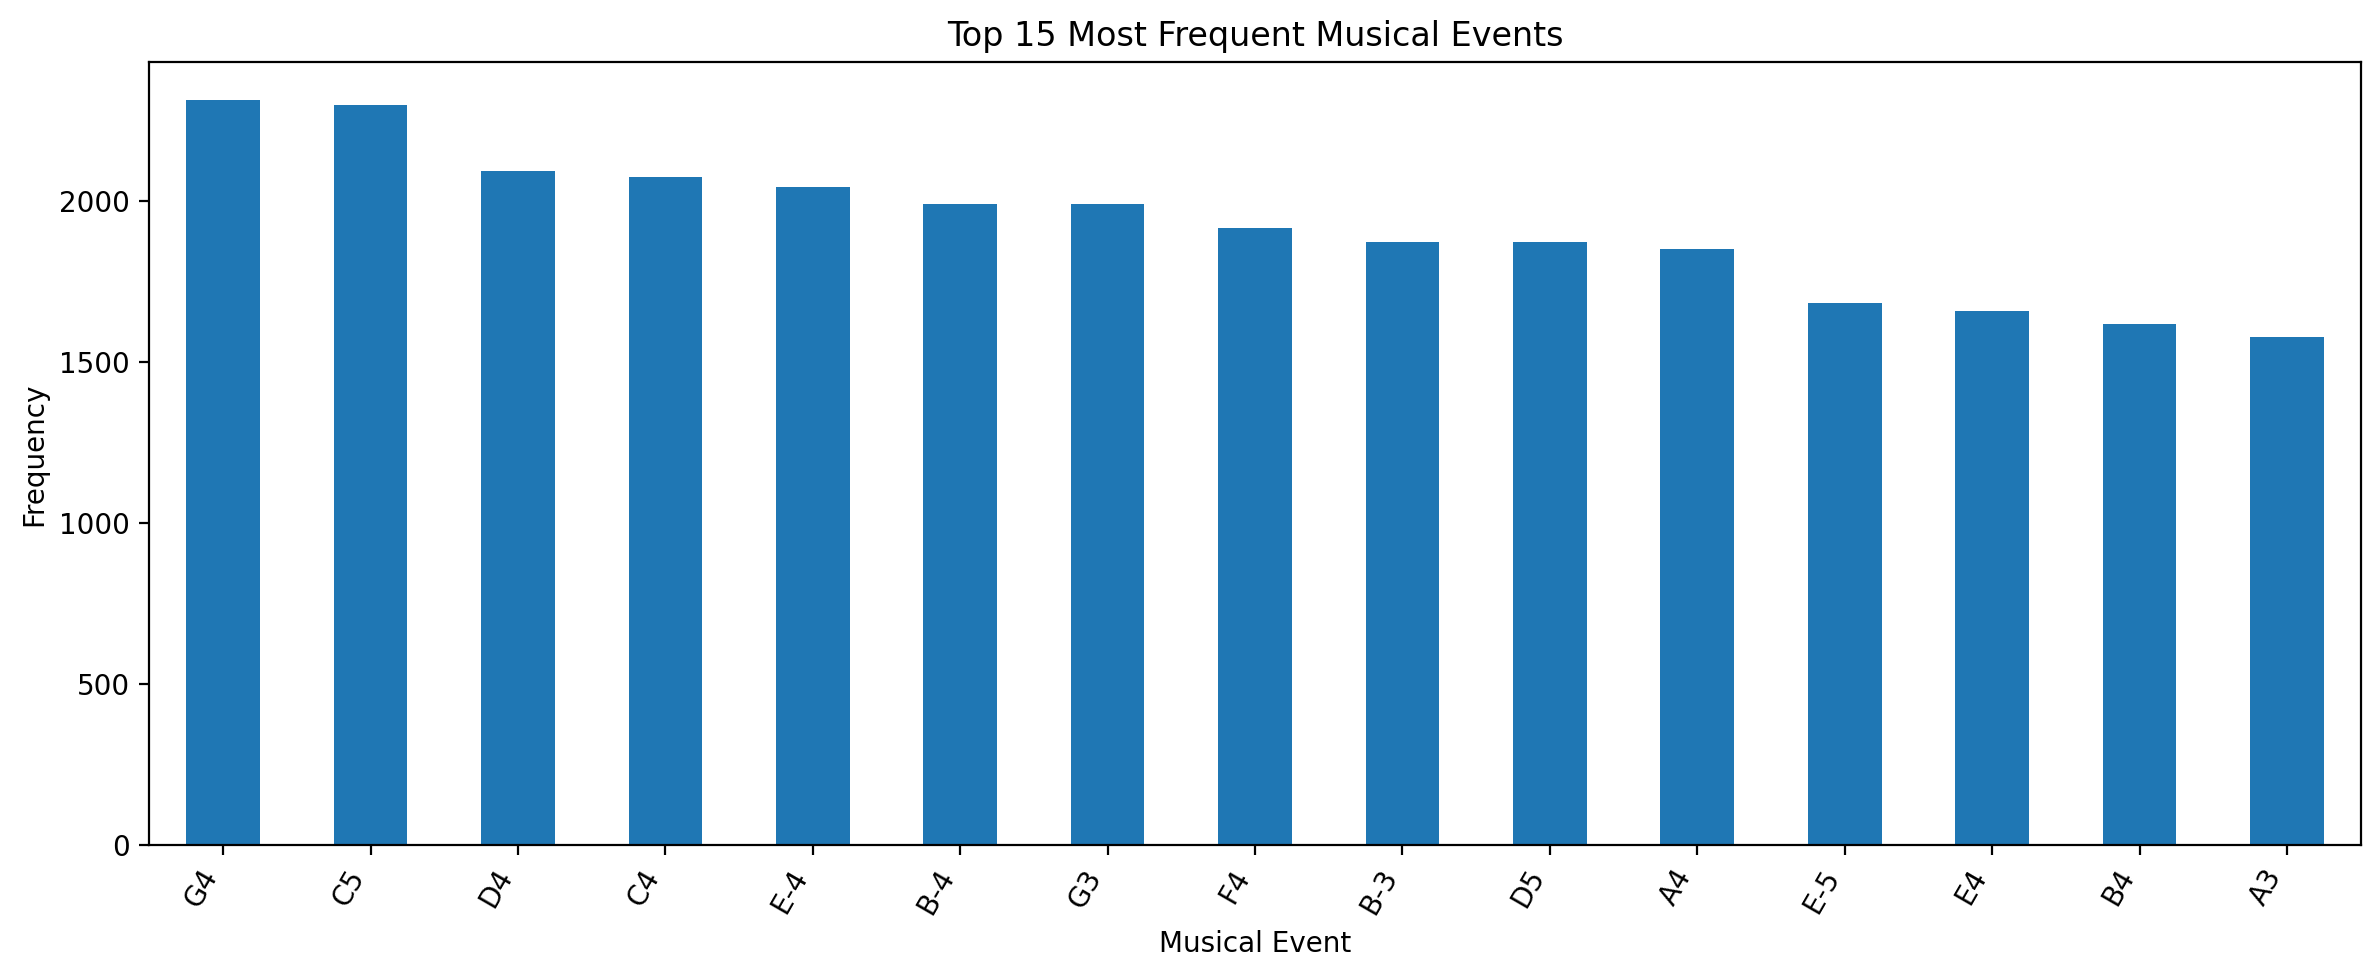

Training sequences: 149903
Input sequence length: 100
Vocabulary size: 1650
X shape: (149903, 100, 1)
y shape: (149903, 1650)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 256)       │       264,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1650)           │       212,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,035,250 (3.95 MB)

 Trainable params: 1,035,250 (3.95 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
2343/2343 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.0133 - loss: 5.6594
Epoch 1: loss improved from None to 5.51935, saving model to /content/best_music_model.keras

Epoch 1: finished saving model to /content/best_music_model.keras
2343/2343 ━━━━━━━━━━━━━━━━━━━━ 2757s 1s/step - accuracy: 0.0148 - loss: 5.5194
Epoch 2/30
1776/2343 ━━━━━━━━━━━━━━━━━━━━ 10:57 1s/step - accuracy: 0.0171 - loss: 5.4140

In [ ]:
!pip -q install music21 pretty_midi tensorflow numpy pandas matplotlib tqdm
!apt-get update -qq
!apt-get install -y -qq timidity

print("Environment setup completed successfully.")

import os
import glob
import random
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from IPython.display import Audio, display

from music21 import converter, instrument, note, chord, stream

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

DATA_URL = "https://storage.googleapis.com/magentadata/datasets/maestro/v3.0.0/maestro-v3.0.0-midi.zip"
ZIP_PATH = "/content/maestro-midi.zip"
DATA_DIR = "/content/maestro_dataset"

if not os.path.exists(DATA_DIR):
    !wget -q "$DATA_URL" -O "$ZIP_PATH"
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Dataset downloaded and extracted.")
else:
    print("Dataset already exists. Skipping download.")

midi_files = glob.glob(os.path.join(DATA_DIR, "**", "*.midi"), recursive=True)
midi_files += glob.glob(os.path.join(DATA_DIR, "**", "*.mid"), recursive=True)
midi_files = sorted(set(midi_files))

print(f"Total MIDI files found: {len(midi_files)}")

DATA_URL = "https://storage.googleapis.com/magentadata/datasets/maestro/v3.0.0/maestro-v3.0.0-midi.zip"
ZIP_PATH = "/content/maestro-midi.zip"
DATA_DIR = "/content/maestro_dataset"

if not os.path.exists(DATA_DIR):
    !wget -q "$DATA_URL" -O "$ZIP_PATH"
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)
    print("Dataset downloaded and extracted.")
else:
    print("Dataset already exists. Skipping download.")

midi_files = glob.glob(os.path.join(DATA_DIR, "**", "*.midi"), recursive=True)
midi_files += glob.glob(os.path.join(DATA_DIR, "**", "*.mid"), recursive=True)
midi_files = sorted(set(midi_files))

print(f"Total MIDI files found: {len(midi_files)}")

for file_path in midi_files[:10]:
    print(file_path)

MAX_FILES = min(50, len(midi_files))
SEQUENCE_LENGTH = 100
EPOCHS = 30
BATCH_SIZE = 64

GENERATE_LENGTH = 300

selected_files = midi_files[:MAX_FILES]

print("Files selected:", len(selected_files))
print("Sequence length:", SEQUENCE_LENGTH)
print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)


def extract_musical_events(file_path):
    """Extract note and chord tokens from a MIDI file."""
    events = []

    try:
        midi = converter.parse(file_path)
        parts = instrument.partitionByInstrument(midi)

        if parts:
            piano_parts = [
                part for part in parts.parts
                if isinstance(part.getInstrument(), instrument.Piano)
            ]
            selected_parts = piano_parts if piano_parts else parts.parts[:1]

            for part in selected_parts:
                for element in part.recurse().notes:
                    if isinstance(element, note.Note):
                        events.append(str(element.pitch))
                    elif isinstance(element, chord.Chord):
                        events.append(".".join(str(n) for n in element.normalOrder))
        else:
            for element in midi.flat.notes:
                if isinstance(element, note.Note):
                    events.append(str(element.pitch))
                elif isinstance(element, chord.Chord):
                    events.append(".".join(str(n) for n in element.normalOrder))

    except Exception as exc:
        print(f"Could not process {os.path.basename(file_path)}: {exc}")

    return events


all_notes = []

for file_path in tqdm(selected_files, desc="Processing MIDI files"):
    all_notes.extend(extract_musical_events(file_path))

print(f"Total musical events extracted: {len(all_notes):,}")
print("First 30 events:")
print(all_notes[:30])

if len(all_notes) == 0:
    raise RuntimeError("No musical events were extracted. Check the MIDI dataset and preprocessing step.")

unique_notes = sorted(set(all_notes))

print("Total events:", len(all_notes))
print("Unique events:", len(unique_notes))
print("Vocabulary coverage ratio:", round(len(unique_notes) / len(all_notes), 4))

event_counts = pd.Series(all_notes).value_counts().head(15)

plt.figure(figsize=(12, 5))
event_counts.plot(kind="bar")
plt.title("Top 15 Most Frequent Musical Events")
plt.xlabel("Musical Event")
plt.ylabel("Frequency")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

note_to_int = {event: i for i, event in enumerate(unique_notes)}
int_to_note = {i: event for event, i in note_to_int.items()}

network_input = []
network_output = []

for i in range(len(all_notes) - SEQUENCE_LENGTH):
    sequence = all_notes[i:i + SEQUENCE_LENGTH]
    next_event = all_notes[i + SEQUENCE_LENGTH]

    network_input.append([note_to_int[event] for event in sequence])
    network_output.append(note_to_int[next_event])

print("Training sequences:", len(network_input))
print("Input sequence length:", SEQUENCE_LENGTH)
print("Vocabulary size:", len(unique_notes))


n_patterns = len(network_input)
X = np.asarray(network_input, dtype=np.float32)
X = np.reshape(X, (n_patterns, SEQUENCE_LENGTH, 1))
X = X / float(len(unique_notes))
y = tf.keras.utils.to_categorical(
    network_output,
    num_classes=len(unique_notes)
    )
print("X shape:", X.shape)
print("y shape:", y.shape)

model = Sequential([
    Input(shape=(X.shape[1], X.shape[2])),
    LSTM(256, return_sequences=True),
    Dropout(0.30),
    LSTM(256),
    Dropout(0.30),
    Dense(128, activation="relu"),
    Dropout(0.30),
    Dense(len(unique_notes), activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

checkpoint = ModelCheckpoint(
    "/content/best_music_model.keras",
    monitor="loss",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X,
    y,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[checkpoint, early_stopping],
    verbose=1
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history["loss"])
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True)

axes[1].plot(history.history["accuracy"])
axes[1].set_title("Training Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best recorded training loss:", min(history.history["loss"]))
print("Best recorded training accuracy:", max(history.history["accuracy"]))


def generate_music(model, network_input, int_to_note, unique_notes, length=300):
    """Generate a new sequence of symbolic musical events."""

    start_index = np.random.randint(0, len(network_input) - 1)
    pattern = list(network_input[start_index])
    generated = []

    for _ in tqdm(range(length), desc="Generating music"):
        prediction_input = np.asarray(pattern, dtype=np.float32)
        prediction_input = np.reshape(
            prediction_input,
            (1, len(pattern), 1)
        )
        prediction_input = prediction_input / float(len(unique_notes))

        prediction = model.predict(prediction_input, verbose=0)[0]

        # Use the highest-probability event for a deterministic baseline.
        predicted_index = int(np.argmax(prediction))

        generated.append(int_to_note[predicted_index])

        pattern.append(predicted_index)
        pattern = pattern[1:]

    return generated


prediction_output = generate_music(
    model,
    network_input,
    int_to_note,
    unique_notes,
    length=GENERATE_LENGTH
)

print("Generated events:", len(prediction_output))
print("First 50 generated events:")
print(prediction_output[:50])

def create_midi(prediction_output, filename="AI_Generated_Music.mid", step=0.5):
    """Create a MIDI file from generated note/chord tokens."""
    offset = 0
    output_notes = []

    for pattern in prediction_output:
        if "." in pattern:
            notes_in_chord = pattern.split(".")
            chord_notes = []

            for current_note in notes_in_chord:
                new_note = note.Note(int(current_note))
                new_note.storedInstrument = instrument.Piano()
                chord_notes.append(new_note)

            new_chord = chord.Chord(chord_notes)
            new_chord.offset = offset
            output_notes.append(new_chord)

        else:
            new_note = note.Note(pattern)
            new_note.offset = offset
            new_note.storedInstrument = instrument.Piano()
            output_notes.append(new_note)

        offset += step

    midi_stream = stream.Stream(output_notes)
    midi_stream.write("midi", fp=filename)

    return filename


MIDI_OUTPUT = "/content/AI_Generated_Music.mid"
create_midi(prediction_output, MIDI_OUTPUT)

print("MIDI file created:", MIDI_OUTPUT)
print("File size:", round(os.path.getsize(MIDI_OUTPUT) / 1024, 2), "KB")


WAV_OUTPUT = "/content/AI_Generated_Music.wav"

!timidity "$MIDI_OUTPUT" -Ow -o "$WAV_OUTPUT" -A 200

if os.path.exists(WAV_OUTPUT):
    print("WAV file created:", WAV_OUTPUT)
    display(Audio(WAV_OUTPUT))
else:
    print("WAV rendering failed. The MIDI file was still created successfully.")

from google.colab import files

print("To download the MIDI file, run:")
print("files.download('/content/AI_Generated_Music.mid')")
print("\nTo download the WAV file, run:")
print("files.download('/content/AI_Generated_Music.wav')")
print("\nTo download the trained model, run:")
print("files.download('/content/best_music_model.keras')")